In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
df=pd.read_csv('../dataset/olist_order_items_dataset.csv')
df.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


In [58]:
df.shape

(112650, 7)

In [59]:
s_df=pd.read_csv('../dataset/olist_sellers_dataset.csv')
p_df=pd.read_csv('../dataset/olist_products_dataset.csv')
o_df=pd.read_csv('../dataset/olist_orders_dataset.csv')
c_df=pd.read_csv('../dataset/olist_customers_dataset.csv')
g_df=pd.read_csv('../dataset/olist_geolocation_dataset.csv')

In [60]:
s_df.head(2)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP


In [61]:
df=df.merge(s_df[['seller_id','seller_state','seller_zip_code_prefix']],on='seller_id',how='left')
df.head(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_state,seller_zip_code_prefix
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,SP,27277
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,SP,3471
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,MG,37564


In [62]:
c_df.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [63]:
o_df=o_df.merge(c_df[['customer_id','customer_state','customer_zip_code_prefix']],on='customer_id',how='left')

In [64]:
df=df.merge(o_df[['order_id','customer_state','customer_zip_code_prefix']],on='order_id',how='left')

In [65]:
df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value', 'seller_state',
       'seller_zip_code_prefix', 'customer_state', 'customer_zip_code_prefix'],
      dtype='object')

In [66]:
df=df.merge(p_df[['product_id', 'product_weight_g','product_length_cm','product_height_cm','product_width_cm']],on='product_id',how='left')

In [67]:
df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value', 'seller_state',
       'seller_zip_code_prefix', 'customer_state', 'customer_zip_code_prefix',
       'product_weight_g', 'product_length_cm', 'product_height_cm',
       'product_width_cm'],
      dtype='object')

In [68]:
df.isnull().sum()

order_id                     0
order_item_id                0
product_id                   0
seller_id                    0
shipping_limit_date          0
price                        0
freight_value                0
seller_state                 0
seller_zip_code_prefix       0
customer_state               0
customer_zip_code_prefix     0
product_weight_g            18
product_length_cm           18
product_height_cm           18
product_width_cm            18
dtype: int64

In [69]:
df.shape

(112650, 15)

In [70]:
df=df.dropna()

In [71]:
df.head(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_state,seller_zip_code_prefix,customer_state,customer_zip_code_prefix,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,SP,27277,RJ,28013,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,SP,3471,SP,15775,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,MG,37564,MG,35661,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,SP,14403,SP,12952,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,PR,87900,SP,13226,3750.0,35.0,40.0,30.0


In [72]:
df['volume_cm3']=df['product_length_cm']*df['product_height_cm']*df['product_width_cm']

In [73]:
df=df.drop(columns=['order_id','order_item_id','product_id','seller_id','shipping_limit_date','product_length_cm','product_height_cm','product_width_cm'])
df.columns

Index(['price', 'freight_value', 'seller_state', 'seller_zip_code_prefix',
       'customer_state', 'customer_zip_code_prefix', 'product_weight_g',
       'volume_cm3'],
      dtype='object')

In [74]:
df.head(2)

,price,freight_value,seller_state,seller_zip_code_prefix,customer_state,customer_zip_code_prefix,product_weight_g,volume_cm3
0,58.9,13.29,SP,27277,RJ,28013,650.0,3528.0
1,239.9,19.93,SP,3471,SP,15775,30000.0,60000.0


In [20]:
df=df[['seller_state','customer_state','product_weight_g','volume_cm3','price','freight_value']]
df.head(2)

,seller_state,customer_state,product_weight_g,volume_cm3,price,freight_value
0,SP,RJ,650.0,3528.0,58.9,13.29
1,SP,SP,30000.0,60000.0,239.9,19.93


In [75]:
df.duplicated().sum()

np.int64(10844)

In [76]:
df=df.drop_duplicates()

In [23]:
num_cols=df.dtypes[df.dtypes!='object'].index
cat_cols=df.dtypes[df.dtypes=='object'].index

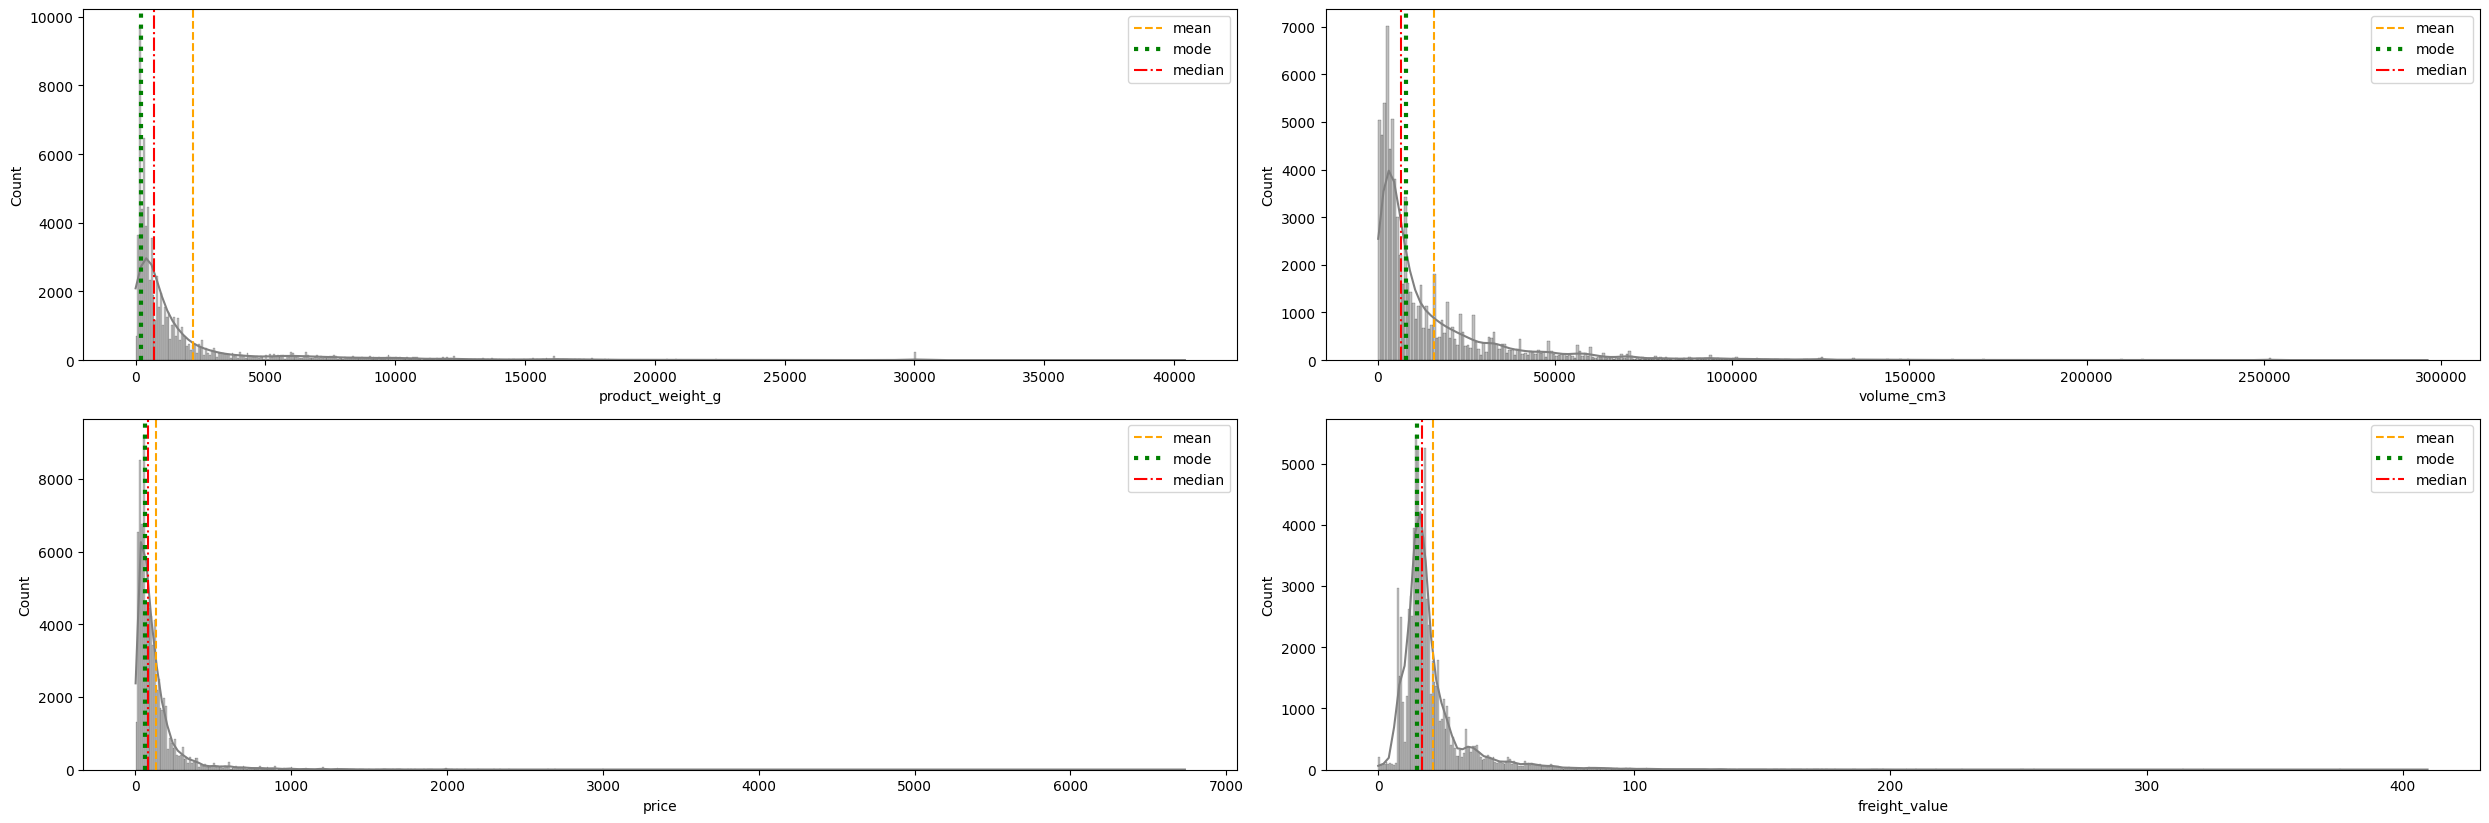

In [24]:
cols=num_cols
plt.figure(figsize=(25,12))
for i in range(len(num_cols)):
    plt.subplot(len(num_cols)//2+1,2,i+1)
    sns.histplot(data=df,x=df[cols[i]],kde=True,color='grey')
    plt.axvline(df[cols[i]].mean(),color='orange',linestyle="--",label='mean')
    plt.axvline(df[cols[i]].mode()[0],color='green',linestyle=":",linewidth=3,label='mode')
    plt.axvline(df[cols[i]].median(),color='red',linestyle="-.",label='median')
    plt.legend()

plt.tight_layout()
plt.show()

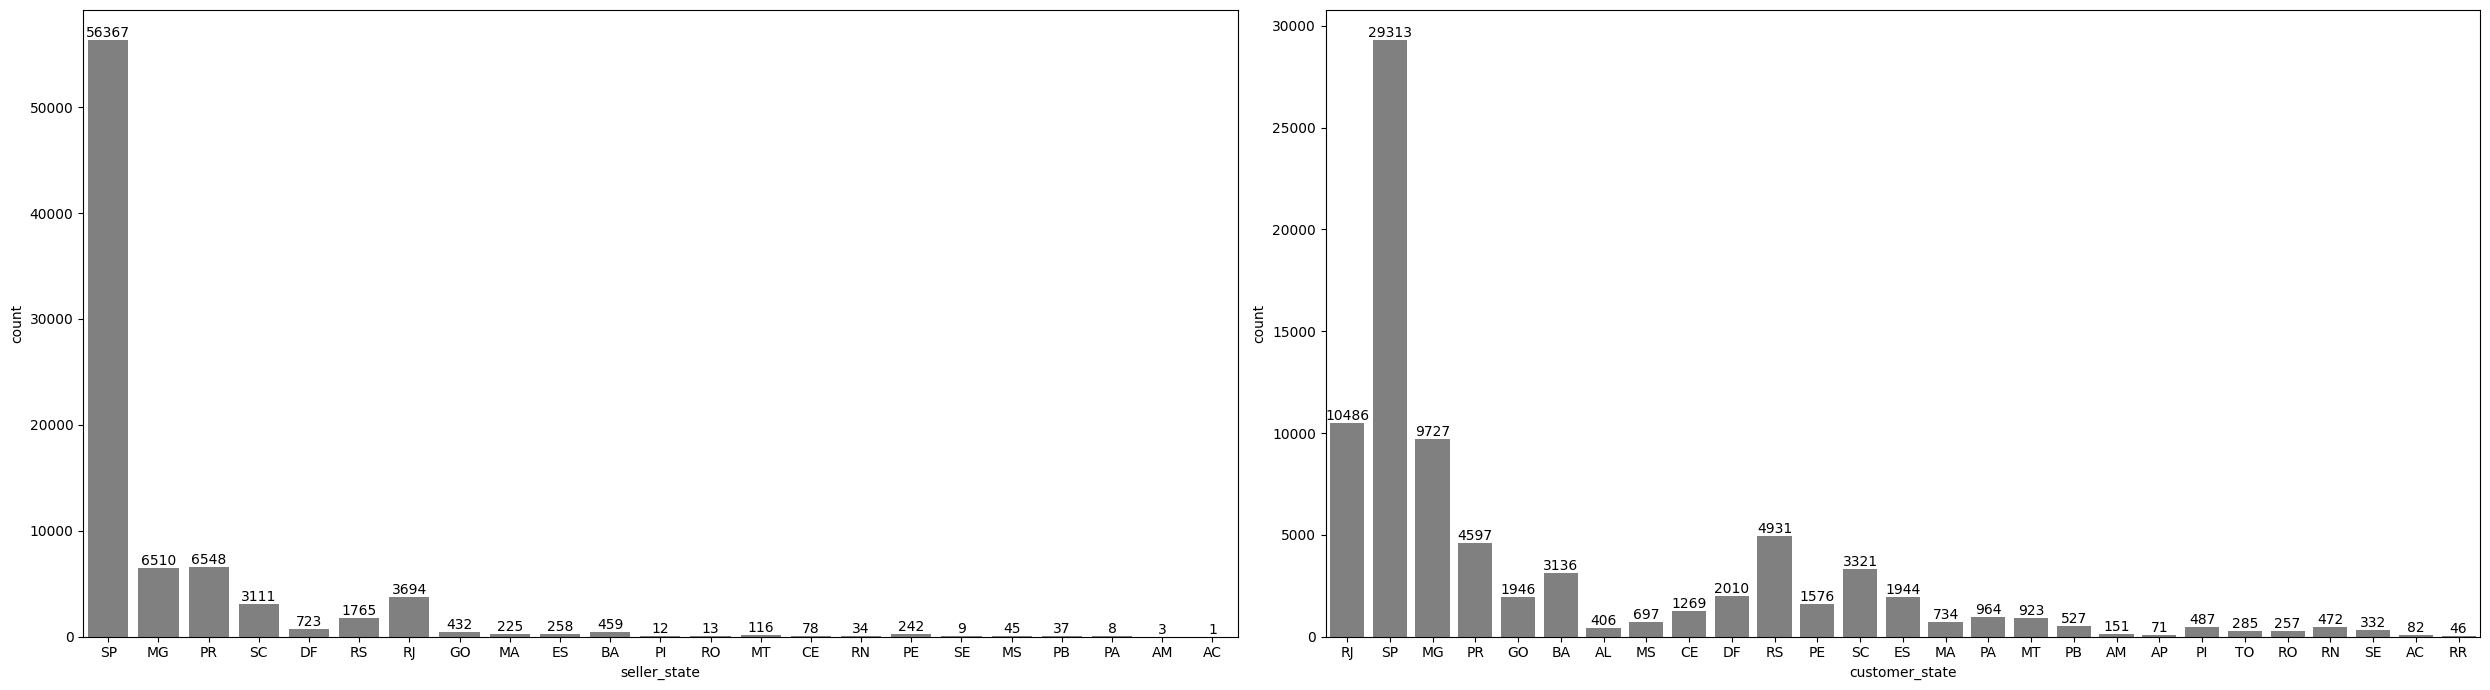

In [52]:
cols=cat_cols
plt.figure(figsize=(25,7))
for i in range(len(cat_cols)):
    plt.subplot(1,2,i+1)
    ax=sns.countplot(data=df,x=df[cols[i]],color='grey')
    plt.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

In [53]:
df['seller_state'].value_counts()

seller_state
SP    56367
PR     6548
MG     6510
RJ     3694
SC     3111
RS     1765
DF      723
BA      459
GO      432
ES      258
PE      242
MA      225
MT      116
CE       78
MS       45
PB       37
RN       34
RO       13
PI       12
SE        9
PA        8
AM        3
AC        1
Name: count, dtype: int64

In [54]:
r=['SE','PA','AM','AC']
df = df[~df['seller_state'].isin(r)]

In [55]:
x1=df[num_cols].describe(percentiles=[0.01,0.02,0.05,0.5,0.95,0.98,0.99]).T
x1=x1.iloc[:,3:]
x1

,min,1%,2%,5%,50%,95%,98%,99%,max
product_weight_g,0.00,75.0000,100.00,125.00,700.00,10100.00,15941.0000,19575.0000,40425.00
volume_cm3,168.00,352.0000,578.00,832.00,6720.00,60000.00,93670.0000,120310.8800,296208.00
price,0.85,10.5000,12.99,18.49,79.90,399.00,699.9900,999.0000,6735.00
freight_value,0.00,5.2836,7.39,7.92,17.03,49.97,69.3828,90.4544,409.68


In [56]:
df=df[df['product_weight_g']<df['product_weight_g'].quantile(0.99)]

In [57]:
x1=df[num_cols].describe(percentiles=[0.01,0.02,0.05,0.5,0.95,0.98,0.99]).T
x1=x1.iloc[:,3:]
x1

,min,1%,2%,5%,50%,95%,98%,99%,max
product_weight_g,0.00,75.00,100.00,125.0000,700.00,9325.0000,13200.0000,16000.00,19550.00
volume_cm3,168.00,352.00,576.00,816.0000,6552.00,56700.0000,80000.0000,98071.92,294000.00
price,0.85,10.49,12.99,18.1585,79.90,379.9000,669.0000,923.87,6729.00
freight_value,0.00,5.23,7.39,7.8900,16.95,46.2915,63.4872,80.11,409.68


In [58]:
df.columns

Index(['seller_state', 'customer_state', 'product_weight_g', 'volume_cm3',
       'price', 'freight_value'],
      dtype='object')

In [59]:
### preparing ml pipeline

In [60]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import RobustScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import *

In [61]:
x=df.iloc[:,:-1]
y=df['freight_value']
x.columns

Index(['seller_state', 'customer_state', 'product_weight_g', 'volume_cm3',
       'price'],
      dtype='object')

In [62]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((55900, 5), (23958, 5), (55900,), (23958,))

In [63]:
num_cols=x.dtypes[x.dtypes!='object'].index
cat_cols=x.dtypes[x.dtypes=='object'].index

In [64]:
cat_pipeline=Pipeline([
    ('encoding',OneHotEncoder(drop='first'))])
num_pipeline=Pipeline([
    ('Rscaler',RobustScaler(quantile_range=(1.0, 96.0)))])

In [65]:
preprocessor=ColumnTransformer([
    ('num_cols',num_pipeline,num_cols),
    ('cat_cols',cat_pipeline,cat_cols)
])

In [66]:
def eval(x_train,y_train,x_test,y_test,model,model_name):
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    r2=model.score(x_test,y_test)
    mse=mean_squared_error(y_test,y_pred)
    mae=mean_absolute_error(y_test,y_pred)
    rmse=np.sqrt(mse)
    e_df=pd.DataFrame({
        'Model': [model_name],
        'R2 Score': [r2],
        'MSE': [mse],
        'RMSE': [rmse],
        'MAE': [mae]
    })
    return e_df

In [38]:
lr_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',LinearRegression(n_jobs=-1))])
lr_eval=eval(x_train,y_train,x_test,y_test,lr_pipeline,'LR')

In [39]:
lr_eval

,Model,R2 Score,MSE,RMSE,MAE
0,LR,0.532216,98.057073,9.902377,5.476498


In [40]:
rf_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',RandomForestRegressor(max_depth=5,criterion='squared_error',min_samples_split=15,verbose=1,n_jobs=-1))])
rf_eval=eval(x_train,y_train,x_test,y_test,rf_pipeline,'RF')

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=24)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=24)]: Done 100 out of 100 | elapsed:    0.0s finished


In [41]:
rf_eval

,Model,R2 Score,MSE,RMSE,MAE
0,RF,0.480546,108.888222,10.434952,5.744449


In [42]:
gb_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',GradientBoostingRegressor(n_estimators=150,max_depth=7,min_samples_split=10,verbose=1))])
gb_eval=eval(x_train,y_train,x_test,y_test,gb_pipeline,'GB')
gb_eval

      Iter       Train Loss   Remaining Time 
         1         186.7499           19.65s
         2         169.0329           18.07s
         3         153.9534           16.84s
         4         141.7303           16.48s
         5         131.4495           16.24s
         6         122.7986           15.90s
         7         115.6766           15.77s
         8         109.6031           15.68s
         9         104.3052           15.37s
        10          99.7600           15.18s
        20          76.4370           13.40s
        30          67.6136           11.68s
        40          62.9381           10.25s
        50          59.6428            8.95s
        60          56.6641            7.83s
        70          54.8566            6.74s
        80          53.4742            5.82s
        90          52.2811            4.91s
       100          50.8372            4.06s


,Model,R2 Score,MSE,RMSE,MAE
0,GB,0.642734,74.890207,8.653913,4.522119


In [56]:
xg_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('model',XGBRegressor(n_estimators=150,max_depth=7,n_jobs=-1))])
xg_eval=eval(x_train,y_train,x_test,y_test,xg_pipeline,'XG')
xg_eval

,Model,R2 Score,MSE,RMSE,MAE
0,XG,0.630301,77.496358,8.803202,4.495846


In [44]:
from sklearn.model_selection import GridSearchCV

In [45]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('rf', RandomForestRegressor(random_state=42))
])

In [46]:
param_grid = {
    'rf__n_estimators': [85,100,150,200],
    'rf__max_depth': [None, 5,7 ,10, 20],
    'rf__min_samples_split': [5, 10, 15],        
    'rf__min_samples_leaf': [2, 4, 6],          
    'rf__max_features': [None , 'sqrt', 'log2'],
    'rf__bootstrap': [True, False]
}
gs_rf=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_rf.fit(x_train, y_train)
  
print("Best params:", gs_rf.best_params_)
print("Best score:", gs_rf.best_score_)
# Best params: {'rf__bootstrap': False, 'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 15, 'rf__n_estimators': 150}
# Best score: 0.6151499082699152

Fitting 5 folds for each of 1080 candidates, totalling 5400 fits
Best params: {'rf__bootstrap': False, 'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 15, 'rf__n_estimators': 150}
Best score: 0.6151499082699152


In [53]:
x2=pd.DataFrame(gs_rf.cv_results_)
x2

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_rf__bootstrap,param_rf__max_depth,param_rf__max_features,param_rf__min_samples_leaf,param_rf__min_samples_split,param_rf__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,84.846451,2.316624,0.272641,0.048832,True,None,None,2,5,85,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.611118,0.623161,0.593948,0.606745,0.594005,0.605796,0.011047,50
1,99.819083,4.223546,0.291278,0.059535,True,None,None,2,5,100,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.612253,0.622518,0.593339,0.607657,0.594884,0.606130,0.010940,47
2,147.476685,3.236886,0.484391,0.090467,True,None,None,2,5,150,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.612559,0.625290,0.593561,0.608208,0.596391,0.607202,0.011488,44
3,192.514681,4.180897,0.602904,0.088733,True,None,None,2,5,200,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.613375,0.625787,0.593726,0.609159,0.596577,0.607725,0.011666,42
4,65.293026,3.364766,0.232829,0.049773,True,None,None,2,10,85,"{'rf__bootstrap': True, 'rf__max_depth': None,...",0.617874,0.625583,0.596450,0.614170,0.600038,0.610823,0.010970,21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1075,27.605883,0.331586,0.232359,0.023772,False,20,log2,6,10,200,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.566411,0.570070,0.559090,0.586052,0.569063,0.570137,0.008836,310
1076,11.763109,0.310291,0.136920,0.013664,False,20,log2,6,15,85,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.565694,0.569455,0.560802,0.585561,0.568816,0.570066,0.008330,319
1077,13.463899,0.747388,0.141713,0.011740,False,20,log2,6,15,100,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.565840,0.569983,0.560626,0.584041,0.569391,0.569976,0.007781,321
1078,18.409227,0.618619,0.143608,0.006453,False,20,log2,6,15,150,"{'rf__bootstrap': False, 'rf__max_depth': 20, ...",0.565753,0.570300,0.561056,0.583635,0.569926,0.570134,0.007536,312


In [54]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('gb', GradientBoostingRegressor(random_state=42))
])
param_grid = {
    'gb__n_estimators': [100, 150, 200],
    'gb__learning_rate': [0.05, 0.1, 0.2],
    'gb__max_depth': [5, 7,10],
    'gb__min_samples_split': [20, 5, 10],
    'gb__min_samples_leaf': [1, 2, 4],
    'gb__subsample': [0.8, 1.0],
    'gb__max_features': [None, 'sqrt', 'log2']
}

gs_gb=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_gb.fit(x_train, y_train)

print("Best params:", gs_gb.best_params_)
print("Best score:", gs_gb.best_score_)
# Best params: {'gb__learning_rate': 0.1, 'gb__max_depth': 10, 'gb__max_features': 'sqrt', 'gb__min_samples_leaf': 4, 'gb__min_samples_split': 10, 'gb__n_estimators': 200, 'gb__subsample': 1.0}
# Best score: 0.6378972915025621


Fitting 5 folds for each of 1458 candidates, totalling 7290 fits
Best params: {'gb__learning_rate': 0.1, 'gb__max_depth': 10, 'gb__max_features': 'sqrt', 'gb__min_samples_leaf': 4, 'gb__min_samples_split': 10, 'gb__n_estimators': 200, 'gb__subsample': 1.0}
Best score: 0.6378972915025621


In [57]:
pipe = Pipeline([
    ('prepr', preprocessor),
    ('xgb', XGBRegressor(random_state=42))
])
param_grid = {
    'xgb__n_estimators': [100, 150,200, 300],
    'xgb__max_depth': [5, 7,10],
    'xgb__learning_rate': [0.01, 0.05, 0.1]
}


gs_xgb=GridSearchCV(estimator=pipe,param_grid=param_grid,cv=5,scoring='r2',n_jobs=-1,verbose=1)
gs_xgb.fit(x_train, y_train)

print("Best params:", gs_xgb.best_params_)
print("Best score:", gs_xgb.best_score_)
# Best params: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 7, 'xgb__n_estimators': 300}
# Best score: 0.6198589856100378

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 7, 'xgb__n_estimators': 300}
Best score: 0.6198589856100378
